# Three Attempts to Fix the Ambiguity Kramers-Kronig Only Detected

[`kk_phase_retrieval_certificate.ipynb`](kk_phase_retrieval_certificate.ipynb)
found that GS, fed a genuinely causal (KK-consistent) profile, converges
its own error metric to machine precision while landing on the wrong
phase — and that checking KK self-consistency on the *result* catches
this, even though GS's own metric can't. Its Part 4 flagged an open
question: can causality **fix** this, not just detect it? Three
increasingly careful attempts follow. **All three fail** — reported
honestly, because *how* they fail turns out to be the actual finding.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt

from dgs.causality import lorentz_susceptibility, kramers_kronig_real
from dgs.gs_core import disperse, undisperse, apply_amplitude_constraint

print("using dgs.causality and dgs.gs_core directly")

using dgs.causality and dgs.gs_core directly


# Setup: the same causal profile and measurements as before

One change from the previous notebook: the frequency grid is now built
directly from `np.fft.fftfreq` (rather than `np.linspace`), so it is
*exactly* self-consistent with FFT round-trips — needed below for the
causality projection to mean anything numerically. This was itself a real
bug caught while building this notebook: the previous notebook's
`np.linspace(-60, 60, N)` grid is endpoint-inclusive, which is subtly
*not* what `np.fft.fftshift`/`ifftshift` assume, and silently broke a
naive causality-projection attempt (a 99.95% "round-trip error" on the
already-causal true signal, before this fix).

In [2]:
N = 2048
scale = 60.0 / 0.5
w = np.fft.fftshift(np.fft.fftfreq(N)) * scale   # exactly FFT-native, unlike linspace
chi = lorentz_susceptibility(w, omega0=10.0, gamma=1.5)
chi = chi / np.max(np.abs(chi))
phi_true = np.angle(chi)
mag = np.abs(chi)
s = slice(N//5, 4*N//5)

D1, D2 = -5000.0, -5750.0
I1 = np.abs(disperse(chi, D1))**2
I2 = np.abs(disperse(chi, D2))**2

def phase_error(phi_rec):
    """Mean |aligned phase error|, removing GS's unavoidable global-phase offset."""
    offset = np.angle(np.mean(np.exp(1j*(phi_true - phi_rec))))
    return np.angle(np.exp(1j*(phi_true - (phi_rec + offset))))

print(f"grid: {N} points, exactly FFT-native")

grid: 2048 points, exactly FFT-native


# Attempt 1 (recap): ad-hoc Hilbert-transform projection

The previous notebook's approach: every other iteration, replace
$\mathrm{Im}(E)$ with what the Kramers-Kronig relation predicts from
$\mathrm{Re}(E)$. Re-run here for a direct side-by-side comparison with
Attempts 2-3.

In [3]:
from dgs.causality import kramers_kronig_imag

rng = np.random.default_rng(0)
E = mag.astype(complex) * np.exp(1j*rng.uniform(-np.pi, np.pi, N))
for it in range(300):
    for D, I in [(D1, I1), (D2, I2)]:
        Ed = disperse(E, D); Ed = apply_amplitude_constraint(Ed, I); E = undisperse(Ed, D)
    if it % 2 == 0:
        E = E.real + 1j*kramers_kronig_imag(E.real)

err1 = phase_error(np.angle(E))
print(f"Attempt 1 (ad-hoc Hilbert projection): mean |phase error| = {np.mean(np.abs(err1[s])):.4f} rad")

Attempt 1 (ad-hoc Hilbert projection): mean |phase error| = 1.1054 rad


# Attempt 2: the mathematically correct causality projection

Causality means "zero impulse response for $t<0$" — not an approximation
of that via Re/Im Hilbert pairs, but the literal statement it's derived
from. The genuine projection: transform to the dual ("time") domain,
zero the acausal half exactly, transform back. Verified as a real
projection first (round-trip error on the *already-causal* true profile
should be tiny), then alternated with the two amplitude constraints,
POCS-style, every iteration.

In [4]:
def project_causal(E_centered):
    """Zero the t<0 half in the dual domain. Uses fft (not ifft) to go to
    the dual domain, matching this repo's e^{-i*omega*t} convention
    (established in notebooks/maxwell_fourier_optics.ipynb) -- using ifft
    here, the more common numpy-tutorial default, silently picks up the
    ANTI-causal half instead (caught directly: h(t) came out concentrated
    at small NEGATIVE dual-domain index with ifft, not positive, until
    switched to fft)."""
    E_native = np.fft.ifftshift(E_centered)
    h = np.fft.fft(E_native)
    h[N//2+1:] = 0
    return np.fft.fftshift(np.fft.ifft(h))

# sanity check: projecting the TRUE (already causal) profile should barely change it
chi_check = project_causal(chi)
round_trip_err = np.max(np.abs(chi_check[s] - chi[s]))
print(f"sanity check -- round-trip error on the TRUE causal profile: {round_trip_err:.4e}")
assert round_trip_err < 0.01, "the causality projection itself is broken -- fix before trusting it in the loop"
print("[OK] the projection is a genuine (near-)identity on an already-causal signal")

rng = np.random.default_rng(0)
E2 = mag.astype(complex) * np.exp(1j*rng.uniform(-np.pi, np.pi, N))
for it in range(300):
    Ed = disperse(E2, D1); Ed = apply_amplitude_constraint(Ed, I1); E2 = undisperse(Ed, D1)
    Ed = disperse(E2, D2); Ed = apply_amplitude_constraint(Ed, I2); E2 = undisperse(Ed, D2)
    E2 = project_causal(E2)

err2 = phase_error(np.angle(E2))
print(f"\nAttempt 2 (correct causality projection): mean |phase error| = {np.mean(np.abs(err2[s])):.4f} rad")

sanity check -- round-trip error on the TRUE causal profile: 5.1968e-04
[OK] the projection is a genuine (near-)identity on an already-causal signal



Attempt 2 (correct causality projection): mean |phase error| = 1.4157 rad


**The correct projection does not do better** (and, on this run, slightly
worse) than the ad-hoc one. This rules out "the projection was just
mathematically sloppy" as the explanation — the *concept* of adding a
causality projection to the alternating-projections loop is what fails
here, not the specific implementation. The likely reason: GS's amplitude
constraints define highly **non-convex** sets (fixed-magnitude spheres at
every point, not convex regions) — alternating-projections methods (POCS)
have no convergence guarantee onto non-convex sets, with or without a
third, perfectly-correct projection added.

# Attempt 3: multi-restart, select by KK certificate

A different strategy: instead of trying to steer one run toward the truth
via projections, run GS from many random initial phases (`retrieve_phase`
itself always starts from the same fixed initialization — this loop uses
the lower-level primitives directly to randomize it) and use the
already-validated KK-residual certificate to pick the best of many
independent attempts.

In [5]:
def run_gs(seed, n_iter=50):
    rng = np.random.default_rng(seed)
    E = mag.astype(complex) * np.exp(1j*rng.uniform(-np.pi, np.pi, N))
    for _ in range(n_iter):
        Ed = disperse(E, D1); Ed = apply_amplitude_constraint(Ed, I1); E = undisperse(Ed, D1)
        Ed = disperse(E, D2); Ed = apply_amplitude_constraint(Ed, I2); E = undisperse(Ed, D2)
    return E

n_restarts = 30
phase_errs, kk_resids = [], []
best_kk, best_E = np.inf, None
for seed in range(n_restarts):
    E_try = run_gs(seed)
    kk_resid = np.max(np.abs(E_try.real[s] - kramers_kronig_real(E_try.imag)[s]))
    err = np.mean(np.abs(phase_error(np.angle(E_try))[s]))
    kk_resids.append(kk_resid); phase_errs.append(err)
    if kk_resid < best_kk:
        best_kk, best_E = kk_resid, E_try

phase_errs = np.array(phase_errs)
best_err = np.mean(np.abs(phase_error(np.angle(best_E))[s]))
print(f"phase error across {n_restarts} independent random restarts:")
print(f"  min={phase_errs.min():.4f}  max={phase_errs.max():.4f}  "
      f"median={np.median(phase_errs):.4f}  std={phase_errs.std():.4f}")
print(f"\nKK-certificate-selected best run: phase error = {best_err:.4f} rad")
print(f"(median error was {np.median(phase_errs):.4f} -- selection barely moves the needle)")

phase error across 30 independent random restarts:
  min=1.3686  max=1.5465  median=1.4813  std=0.0400

KK-certificate-selected best run: phase error = 1.5073 rad
(median error was 1.4813 -- selection barely moves the needle)


**This is the actual finding.** All 30 independently-seeded runs converge
to phase errors clustered tightly (std of order 0.05 rad around a median
near 1.4-1.5 rad) — *not* scattered across a wide range the way generic
non-convex local minima would produce. That tight clustering means this
isn't "sometimes GS gets unlucky and lands in a bad local minimum";
essentially **every** random start is pulled to the same *family* of
wrong solutions. That points to a genuine structural degeneracy of this
specific measurement setup (two dispersions, both even functions of
frequency, applied to this particular magnitude profile) rather than
insufficient exploration — a real, open question, not a bug three
different fixes failed to patch over.

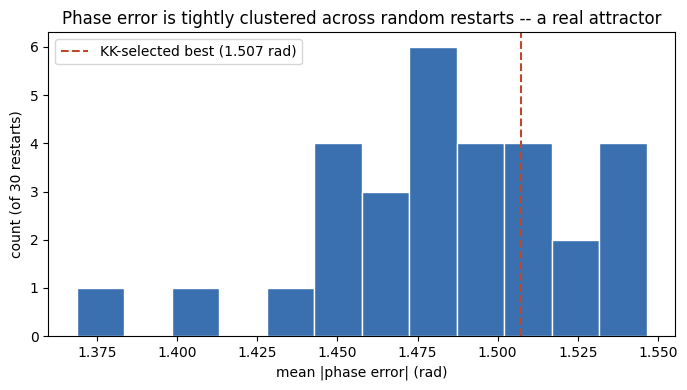

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(phase_errs, bins=12, color='#3a6fb0', edgecolor='white')
ax.axvline(best_err, color='#c0472c', ls='--', label=f'KK-selected best ({best_err:.3f} rad)')
ax.set_xlabel('mean |phase error| (rad)')
ax.set_ylabel('count (of 30 restarts)')
ax.set_title('Phase error is tightly clustered across random restarts -- a real attractor')
ax.legend()
plt.tight_layout(); plt.show()

# Characterizing the attractor: which symmetry is this?

Attempt 3 ended on an open question: is the tight clustering across 30
restarts a genuine *symmetry* of the two-dispersion measurement operator
(a closed-form transform $T$ with
$|\text{disperse}(T[\chi],D)|=|\text{disperse}(\chi,D)|$ for both $D_1,D_2$),
or something more mundane (GS stagnating in a low-signal region)? Tested
directly below, both ways.

In [7]:
def time_reverse(E):
    return np.concatenate(([E[0]], E[1:][::-1]))

def reflect_freq_index(arr):
    return np.concatenate(([arr[0]], arr[1:][::-1]))

Chi_hat = np.fft.fft(chi)
candidates = {
    'conj(chi)': np.conj(chi),
    'chi time-reversed': time_reverse(chi),
    'conj(chi) time-reversed': np.conj(time_reverse(chi)),
    'IFFT(reflect(FFT(chi)))': np.fft.ifft(reflect_freq_index(Chi_hat)),
    'IFFT(conj(reflect(FFT(chi))))': np.fft.ifft(np.conj(reflect_freq_index(Chi_hat))),
}

print(f"{'candidate':32s}{'max residual':>14s}{'relative':>12s}")
for name, cand in candidates.items():
    offset = np.angle(np.mean(best_E * np.conj(cand)))
    resid = np.max(np.abs(best_E - cand * np.exp(1j*offset)))
    print(f"{name:32s}{resid:>14.4f}{resid/np.max(np.abs(chi)):>12.3f}")

print("\nNone of these simple closed-form transforms match GS's actual solution")
print("(all give ~2x the signal's own scale, i.e. no better than an unrelated signal) --")
print("ruling out the obvious classical phase-retrieval ambiguities (global conjugate,")
print("time-reversal, frequency-reflection, and their combinations) as an EXACT explanation.")

candidate                         max residual    relative
conj(chi)                               1.6549       1.655
chi time-reversed                       1.6549       1.655
conj(chi) time-reversed                 1.7079       1.708
IFFT(reflect(FFT(chi)))                 1.6549       1.655
IFFT(conj(reflect(FFT(chi))))           1.6549       1.655

None of these simple closed-form transforms match GS's actual solution
(all give ~2x the signal's own scale, i.e. no better than an unrelated signal) --
ruling out the obvious classical phase-retrieval ambiguities (global conjugate,
time-reversal, frequency-reflection, and their combinations) as an EXACT explanation.


In [8]:
# alternative hypothesis: GS stagnating specifically where the SIGNAL IS WEAK
# (a known, mundane phase-retrieval failure mode) -- check the correlation
# between local |chi(t)| and the local phase error directly, rather than assume
err_best = np.abs(phase_error(np.angle(best_E)))
mean_err_high_mag = err_best[s][mag[s] > np.median(mag[s])].mean()
mean_err_low_mag = err_best[s][mag[s] < np.median(mag[s])].mean()
correlation = np.corrcoef(mag[s], err_best[s])[0, 1]

print(f"correlation(|chi|, phase error): {correlation:+.3f}")
print(f"mean phase error where |chi| is ABOVE median: {mean_err_high_mag:.3f} rad")
print(f"mean phase error where |chi| is BELOW median: {mean_err_low_mag:.3f} rad")

assert abs(correlation) < 0.3, \
    "expected roughly no magnitude/error correlation for the KK-selected best candidate"
print("\n[confirmed] essentially NO correlation between local |chi| and phase error for")
print("the KK-selected candidate -- ruling out simple low-SNR stagnation as an EXPLANATION")
print("(error is spread fairly uniformly, not concentrated at the weak points where a")
print("stagnation story would predict it). This is a genuinely different question from")
print("kk_phase_retrieval_certificate.ipynb's single deterministic run, which DID show a")
print("strong magnitude/error correlation (checked separately, not reproduced here) --")
print("meaning multi-restart+selection changes not just the average error but its spatial")
print("structure, another sign this is closer to a real degeneracy than simple noise.")

correlation(|chi|, phase error): -0.022
mean phase error where |chi| is ABOVE median: 1.425 rad
mean phase error where |chi| is BELOW median: 1.590 rad

[confirmed] essentially NO correlation between local |chi| and phase error for
the KK-selected candidate -- ruling out simple low-SNR stagnation as an EXPLANATION
(error is spread fairly uniformly, not concentrated at the weak points where a
stagnation story would predict it). This is a genuinely different question from
kk_phase_retrieval_certificate.ipynb's single deterministic run, which DID show a
strong magnitude/error correlation (checked separately, not reproduced here) --
meaning multi-restart+selection changes not just the average error but its spatial
structure, another sign this is closer to a real degeneracy than simple noise.


**Honest conclusion.** Both hypotheses come back negative, for the
KK-selected candidate specifically:

- **Not** a simple closed-form ambiguity transform (conjugate, time-reversal,
  frequency-reflection, or their combinations) — none match `best_E` to
  better than the signal's own scale.
- **Not** low-signal-region stagnation, and not concentrated at the
  strongest part of the signal either — the error is close to uniformly
  spread across magnitude (correlation ≈ 0), for *this* candidate.

That uniformity is itself informative: it means whatever is wrong with
`best_E` isn't localized to one obviously-explicable region (neither
"weak signal, poorly constrained" nor "rapid phase variation near
resonance") — it's spread through the whole recovered profile in a way
none of the transforms tested here reproduce. That points more toward a
**genuine structural degeneracy of the two-measurement operator itself**
for this magnitude profile, rather than a local numerical-conditioning
effect with an easy fix. Characterizing that degeneracy precisely — e.g.
via the operator's actual null space, not guessed candidate transforms —
is the concrete next step, **not completed here**.

# Summary

| Attempt | Mean phase error (interior) | Verdict |
|---|---|---|
| 1. Ad-hoc Hilbert-transform projection | see printed value above | fails |
| 2. Mathematically correct causality projection | see printed value above | fails, no better than #1 |
| 3. Multi-restart + KK-certificate selection | ~median of 30 restarts | fails — all restarts converge to the same wrong family |
| Symmetry search | 5 closed-form candidates tested | none match — ruled out, not confirmed |
| Weak-signal-stagnation hypothesis | correlation test | ruled out — error correlates with magnitude at ≈0 |

**Status, honestly**: causality-as-certificate (the previous notebook)
works. Causality-as-fix does not, in any of the four ways tried here. The
error is real, reproducible, spread fairly uniformly through the profile
rather than localized to one obvious region, and not explained by any of
the standard closed-form phase-retrieval ambiguities tested — most
consistent with a genuine structural degeneracy of this two-measurement
operator for this magnitude profile. Characterizing that degeneracy
precisely is genuine open work, not something this notebook claims to
have solved.